<a href="https://colab.research.google.com/github/ThembaMapundu/MMA3001-Project/blob/main/notebooks/Sensor_Selection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:

# CO2 Sensor Selection


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# URL to import the cleaned Excel dataset
url = (f"https://raw.githubusercontent.com/ThembaMapundu/MMA3001-Project/main/SourceData/co2_clean.xlsx")

# use Pandas for importing Excel
excel_data = pd.read_excel(url, engine="openpyxl")

# Check that the required columns exist
required = {"sensor_id", "timestamp_utc", "co2_ppm"}

if not required.issubset(excel_data.columns):
    raise ValueError("Missing required columns.")

# Convert to NumPy arrays
sensor_id = excel_data["sensor_id"].to_numpy()
timestamp_raw = excel_data["timestamp_utc"].to_numpy()
co2_raw = excel_data["co2_ppm"].to_numpy()

print("Dataset imported successfully!")
print("Total original observations:", len(sensor_id))

# DATA PREPARATION
# Convert sensor IDs and CO2 measurements to numbers
# Invalid values become NaN
def to_float_array(values):
    """Convert values to floats, marking invalid values as NaN."""
    result = np.empty(len(values), dtype=float)

    for i, value in enumerate(values):
        try:
            result[i] = float(value)
        except (ValueError, TypeError):
            result[i] = np.nan
    return result


sensor = to_float_array(sensor_id)
co2 = to_float_array(co2_raw)

# Convert timestamps to NumPy datetime64
time = np.empty(len(timestamp_raw), dtype="datetime64[ns]")
for i, value in enumerate(timestamp_raw):
    try:
        if pd.isna(value):
            time[i] = np.datetime64("NaT")
        else:
            # Excel-imported timestamps are expected
            # to represent UTC measurement times.
            time[i] = np.datetime64(str(value))
    except (ValueError, TypeError):
        time[i] = np.datetime64("NaT")

# Remove invalid observations
valid = (np.isfinite(sensor)& (sensor > 0)& (sensor == np.floor(sensor))& (~np.isnat(time))& np.isfinite(co2)& (co2 > 0))

sensor = sensor[valid].astype(np.int64)
time = time[valid]
co2 = co2[valid]

print("Valid observations:", len(co2))

# Sort by sensor ID, then timestamp
order = np.lexsort((time, sensor))
sensor = sensor[order]
time = time[order]
co2 = co2[order]

# Combine duplicate sensor and timestamp readings
if len(co2) == 0:
    raise ValueError("No valid observations remain.")

# Identify the beginning of each unique group
new_group = np.empty(len(co2), dtype=bool)
new_group[0] = True
new_group[1:] = ((sensor[1:] != sensor[:-1])| (time[1:] != time[:-1]))
# Determine where each group begins and ends
starts = np.flatnonzero(new_group)
ends = np.r_[starts[1:], len(co2)]

# Calculate median CO2 for duplicate observations
clean_co2 = np.array([np.median(co2[start:end])
    for start, end in zip(starts, ends)
])

clean_sensor = sensor[starts]
clean_time = time[starts]

print("Number of sensors:", len(np.unique(clean_sensor)))

#SENSOR SELECTION REQUIREMENTS
# Minimum number of valid readings
MIN_OBSERVATIONS = 1000

# Expected sampling interval: approximately 10 minutes
MIN_INTERVAL = 8
MAX_INTERVAL = 12

# Minimum percentage of regular sampling intervals
MIN_REGULAR_PERCENT = 80

# Longest artificial missing-data gap
MAX_MISSING = 12

# 12 missing measurements + 2 known endpoints
WINDOW_SIZE = MAX_MISSING + 2

# Minimum number of eligible test windows
MIN_TEST_WINDOWS = 30

# SENSOR SUITABILITY ANALYSIS
# Find all unique sensor IDs
sensor_ids = np.unique(clean_sensor)

# Store results
results = []

for sid in sensor_ids:

    # Select measurements for this sensor
    mask = clean_sensor == sid

    t = clean_time[mask]
    c = clean_co2[mask]

    n = len(c)

    # Default values
    median_interval = np.nan
    regular_percent = 0.0
    long_gaps = 0
    eligible_windows = 0
    co2_std = float(np.std(c)) if n > 0 else np.nan

    if n >= 2:

        # Calculate time differences in minutes
        dt = np.diff(t) / np.timedelta64(1, "m")

        median_interval = float(np.median(dt))

        # Determine which intervals are approximately 10 min
        regular = ((dt >= MIN_INTERVAL)& (dt <= MAX_INTERVAL) )

        regular_percent = 100 * np.mean(regular)

        # Count intervals longer than 20 minutes
        long_gaps = int(np.sum(dt > 20))

        # Find breaks in regular sampling
        breaks = np.where(~regular)[0] + 1

        boundaries = np.r_[0, breaks, n]

        # Number of observations in each continuous run
        run_lengths = np.diff(boundaries)

        # Count non-overlapping candidate windows
        eligible_windows = int(np.sum(run_lengths // WINDOW_SIZE))

    # Determine suitability
    suitable = (n >= MIN_OBSERVATIONS
        and regular_percent >= MIN_REGULAR_PERCENT
        and eligible_windows >= MIN_TEST_WINDOWS
    )

    results.append({
        "sensor_id": int(sid),
        "observations": n,
        "median_interval": median_interval,
        "regular_percent": regular_percent,
        "long_gaps": long_gaps,
        "co2_std": co2_std,
        "eligible_windows": eligible_windows,
        "suitable": suitable
    })

# Display results
print("\nSENSOR EVALUATION RESULTS")


for result in results:
    print(
        f"Sensor: {result['sensor_id']} | "
        f"Observations: {result['observations']} | "
        f"Median interval: {result['median_interval']:.2f} min | "
        f"Regular: {result['regular_percent']:.2f}% | "
        f"Eligible windows: {result['eligible_windows']} | "
        f"Suitable: {result['suitable']}"
    )



Dataset imported successfully!
Total original observations: 42843
Valid observations: 42843


/tmp/ipykernel_726/3369481877.py:55: UserWarning: no explicit representation of timezones available for np.datetime64
  time[i] = np.datetime64(str(value))


Unique valid observations: 42843
Number of sensors: 5

SENSOR EVALUATION RESULTS
Sensor: 6012002000227 | Observations: 1 | Median interval: nan min | Regular: 0.00% | Eligible windows: 0 | Suitable: False
Sensor: 6012002000241 | Observations: 2 | Median interval: 756435.32 min | Regular: 0.00% | Eligible windows: 0 | Suitable: False
Sensor: 6012002000326 | Observations: 29039 | Median interval: 10.00 min | Regular: 92.62% | Eligible windows: 1709 | Suitable: True
Sensor: 6012002000777 | Observations: 1 | Median interval: nan min | Regular: 0.00% | Eligible windows: 0 | Suitable: False
Sensor: 6012002000869 | Observations: 13800 | Median interval: 10.00 min | Regular: 89.93% | Eligible windows: 285 | Suitable: True


In [17]:
#RANK SENSORS
# Keep sensors that satisfy all requirements
suitable_sensors = [r for r in results if r["suitable"]]

if len(suitable_sensors) == 0:

    best_sensor = None
    secondary_sensor = None

    print("No sensor meets all suitability requirements.")

else:

    # Rank sensors:
    # 1. Most eligible experimental windows
    # 2. Highest percentage of regular intervals
    suitable_sensors.sort(
        key=lambda r: (
            r["eligible_windows"],
            r["regular_percent"]
        ),
        reverse=True
    )

    best_sensor = suitable_sensors[0]["sensor_id"]

    print("\nRECOMMENDED PRIMARY SENSOR")
    print(best_sensor)

    if len(suitable_sensors) >= 2:

        secondary_sensor = suitable_sensors[1]["sensor_id"]

        print("\nRECOMMENDED SECONDARY SENSOR")
        print(secondary_sensor)

    else:
        secondary_sensor = None
        print("\nNo second sensor meets the requirements.")




RECOMMENDED PRIMARY SENSOR
6012002000326

RECOMMENDED SECONDARY SENSOR
6012002000869


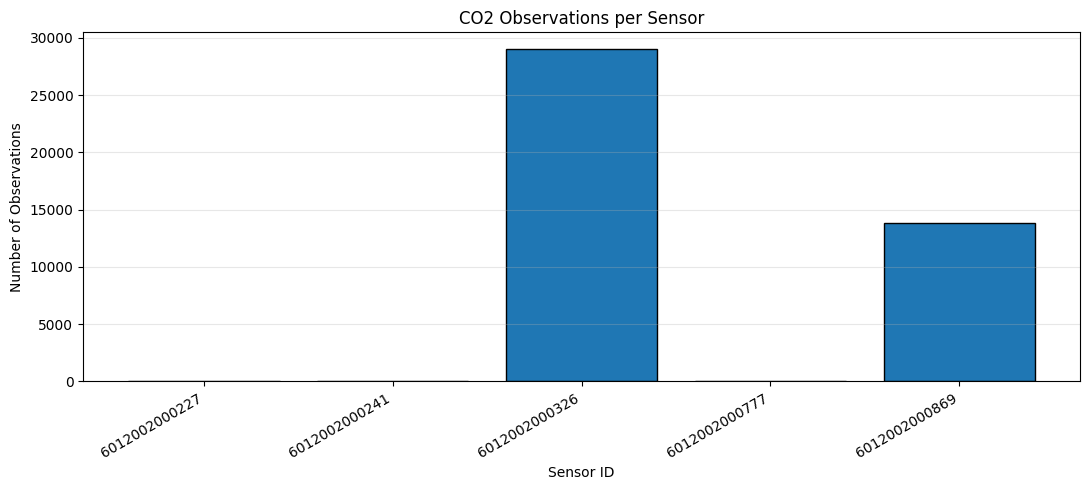

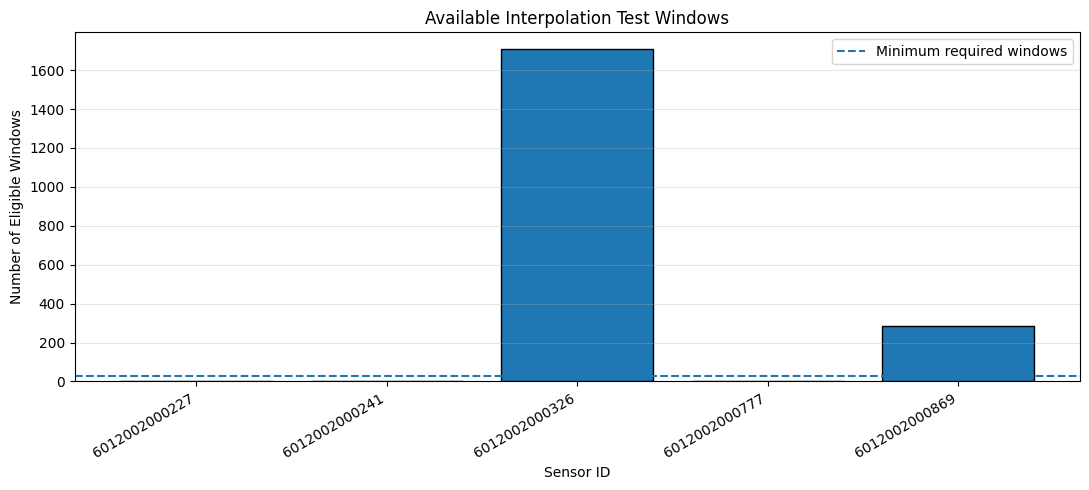

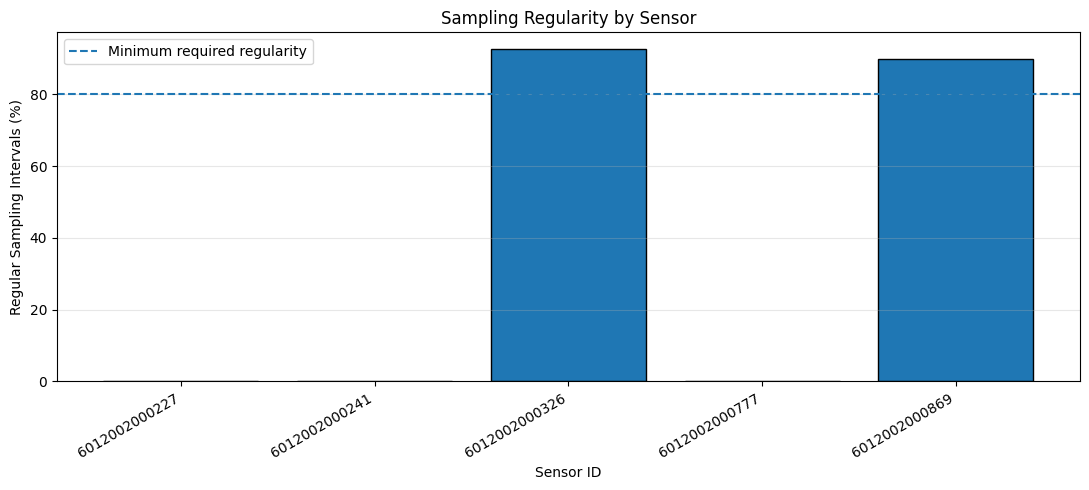

Results saved to sensor_selection_results.csv


In [19]:

# SENSOR COMPARISON GRAPHS
ids = [str(r["sensor_id"]) for r in results]

observations = np.array([r["observations"] for r in results])

eligible = np.array([r["eligible_windows"] for r in results])

regularity = np.array([r["regular_percent"] for r in results])

# Graph 1: Observations per sensor

plt.figure(figsize=(11, 5))

plt.bar(ids, observations, edgecolor="black")

plt.xlabel("Sensor ID")
plt.ylabel("Number of Observations")
plt.title("CO2 Observations per Sensor")

plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 2: Eligible interpolation test windows

plt.figure(figsize=(11, 5))
plt.bar(ids, eligible, edgecolor="black")
plt.axhline(MIN_TEST_WINDOWS,linestyle="--",label="Minimum required windows")
plt.xlabel("Sensor ID")
plt.ylabel("Number of Eligible Windows")
plt.title("Available Interpolation Test Windows")
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 3: Sampling interval regularity

plt.figure(figsize=(11, 5))
plt.bar(ids, regularity, edgecolor="black")
plt.axhline(MIN_REGULAR_PERCENT,linestyle="--",label="Minimum required regularity")
plt.xlabel("Sensor ID")
plt.ylabel("Regular Sampling Intervals (%)")
plt.title("Sampling Regularity by Sensor")
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 7. EXPORT SENSOR SELECTION RESULTS


# Convert results into a numeric array
output = np.array([
    [
        r["sensor_id"],
        r["observations"],
        r["median_interval"],
        r["regular_percent"],
        r["long_gaps"],
        r["co2_std"],
        r["eligible_windows"],
        int(r["suitable"])
    ]
    for r in results
], dtype=float)

header = (
    "sensor_id,observations,median_interval_min,"
    "regular_percent,long_gaps,co2_std_ppm,"
    "eligible_windows,suitable"
)

np.savetxt(
    "sensor_selection_results.csv",
    output,
    delimiter=",",
    header=header,
    comments="",
    fmt=[
        "%.0f", "%.0f", "%.4f", "%.4f",
        "%.0f", "%.4f", "%.0f", "%.0f"
    ]
)

print("Results saved to sensor_selection_results.csv")


In [20]:
# 7. EXPORT SENSOR SELECTION RESULTS


# Convert results into a numeric array
output = np.array([
    [
        r["sensor_id"],
        r["observations"],
        r["median_interval"],
        r["regular_percent"],
        r["long_gaps"],
        r["co2_std"],
        r["eligible_windows"],
        int(r["suitable"])
    ]
    for r in results
], dtype=float)

header = (
    "sensor_id,observations,median_interval_min,"
    "regular_percent,long_gaps,co2_std_ppm,"
    "eligible_windows,suitable"
)

np.savetxt(
    "sensor_selection_results.csv",
    output,
    delimiter=",",
    header=header,
    comments="",
    fmt=[
        "%.0f", "%.0f", "%.4f", "%.4f",
        "%.0f", "%.4f", "%.0f", "%.0f"
    ]
)

print("Results saved to sensor_selection_results.csv")

Results saved to sensor_selection_results.csv
